# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [4]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [5]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [6]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [7]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [8]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [10]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [11]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [12]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [13]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [14]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [15]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?


**Diagnóstico de valores nulos**

*users (4,000 filas):*
- `city`: 469 nulos (11.73%). Está en el rango de 5–30%, así que se investiga. Como la ciudad no se puede deducir de otra columna, se **dejan como nulos**. Además, en el `head()` aparece el valor `"?"`, que es un faltante disfrazado y aumentará este porcentaje.
- `churn_date`: 3,534 nulos (88.35%). Aunque supera el 80%, no es un error de captura: el nulo indica que el cliente **no ha cancelado** (sigue activo). Se **mantiene como está** y no se usa para el análisis de uso.
- El resto de columnas (`user_id`, `first_name`, `last_name`, `age`, `reg_date`, `plan`) no tiene nulos.

*usage (40,000 filas):*
- `date`: 50 nulos (0.13%). Es menos del 5%, así que se **dejan como nulos**; su impacto en el análisis es mínimo.
- `duration`: 22,076 nulos (55.19%) y `length`: 17,896 nulos (44.74%). Son nulos **estructurales**: `duration` solo aplica a llamadas y `length` solo a mensajes, por eso cada una está vacía en el tipo que no le corresponde. Se **dejan como nulos** y en el paso 3.2 se confirmará si dependen de `type` (MAR).
- `id`, `user_id` y `type` no tienen nulos.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [16]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` va de 10000 a 13999 con 4,000 registros, lo que indica IDs consecutivos y sin valores inválidos.
- La columna `age` tiene un mínimo de **-999**, que es un **sentinel** (una edad negativa es imposible). Este valor distorsiona la media (33.7) y la desviación estándar (123.2). La mediana (47) y el máximo (79) sí son razonables, así que el problema está solo en el sentinel.

In [17]:
# explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id` no presentan problemas: `id` va de 1 a 40,000 (identificador consecutivo) y `user_id` va de 10000 a 13999, el mismo rango que en `users`.
- Las columnas `duration` y `length` no tienen valores negativos ni sentinels. Ambas tienen mínimo 0 (llamadas sin duración o mensajes vacíos) y máximos alejados de la mediana: `duration` llega a 120 minutos con mediana de 3.5, y `length` llega a 1,490 caracteres con mediana de 50. Esto indica posibles **outliers**, que se revisarán en el paso 5.

In [18]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']

for col in columnas_user:
    print(users[col].value_counts(dropna=False))
    print()

Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

Basico     2595
Premium    1405
Name: plan, dtype: int64



- La columna `city` tiene 96 registros con el valor **"?"**, que es un **sentinel**. Sumados a los 469 nulos, dan 565 registros sin ciudad (14.1%). Las ciudades restantes (Bogotá, CDMX, Medellín, GDL, Cali, MTY) no tienen variaciones de escritura.
- La columna `plan` está limpia: solo tiene "Basico" (2,595 usuarios, 64.9%) y "Premium" (1,405 usuarios, 35.1%).

In [19]:
# explorar columna categórica de usage
usage['type'].value_counts(dropna=False)

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` está limpia: solo tiene "text" (22,092 registros) y "call" (17,908 registros), sin nulos ni valores inválidos.

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?


**Diagnóstico**

**¿En qué columnas encontraste valores inválidos o sentinels?**
- `age`: tiene el sentinel **-999**, una edad imposible que distorsiona la media (33.7) y la desviación estándar (123.2).
- `city`: tiene el sentinel **"?"** en 96 registros, que representa una ciudad desconocida.
- `duration` y `length`: no tienen sentinels, pero sí valores extremos (120 minutos y 1,490 caracteres) que podrían ser outliers.
- `user_id`, `id`, `plan` y `type` no presentan valores inválidos.

**¿Qué acción tomarías?**
- `age`: reemplazar -999 por la **mediana**, porque no se ve afectada por el sentinel y conserva todos los registros.
- `city`: reemplazar "?" por **nulo** (`pd.NA`), porque no es posible saber la ciudad real; así quedan 565 nulos en total (14.1%).
- `duration` y `length`: **mantenerlos por ahora** y analizarlos como outliers en el paso 5 antes de decidir si se eliminan.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [20]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [21]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [22]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En `reg_date`, los registros se reparten de forma muy similar entre 2022 (1,314), 2023 (1,316) y 2024 (1,330). Sin embargo, hay **40 registros con año 2026** (1% de los usuarios), un año que no había transcurrido al momento de guardar los datos (hasta 2024). Son fechas imposibles, probablemente errores de captura. No hay fechas nulas ni que hayan fallado en la conversión.

In [23]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts(dropna=False).sort_index()

2024.0    39950
NaN          50
Name: date, dtype: int64

En `date`, todos los registros válidos corresponden a **2024** (39,950), por lo que no hay años imposibles. Los 50 valores `NaN` son los mismos nulos detectados en el paso 2.1, no errores de la conversión.
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

**Diagnóstico**

**¿Aparecen años imposibles?**
- Sí, en `reg_date` hay **40 registros con año 2026**, un año que no había transcurrido cuando se guardaron los datos (hasta 2024). Representan el 1% de los usuarios.
- En `date` no hay años imposibles: todas las fechas válidas son de 2024 y solo hay 50 nulos (0.13%).

**¿Qué harías con ellas?**
- `reg_date`: marcar las 40 fechas de 2026 como **nulas** (`pd.NA`). No se eliminan los usuarios porque su información de uso, edad y plan sigue siendo válida, y la fecha de registro no es necesaria para el análisis de consumo.
- `date`: **dejar los 50 nulos** como están, porque son muy pocos y no afectan el análisis.
- No se imputan con la mediana porque una fecha es un evento puntual: asignar la misma fecha a varios registros crearía información falsa, y estas columnas no se usan para calcular las métricas de uso.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [41]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [42]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].value_counts(dropna=False)

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [43]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()

2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [44]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration'].isna().groupby(usage['type']).mean()

type
call    0.000000
text    0.999276
Name: duration, dtype: float64

In [45]:
# Verificación MAR en usage (Missing At Random) para length
usage['length'].isna().groupby(usage['type']).mean()

type
call    0.99933
text    0.00000
Name: length, dtype: float64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

**Diagnóstico de nulos en `duration` y `length`**

- `duration`: tiene **0% de nulos en llamadas** y **99.93% de nulos en mensajes**. Es decir, todas las llamadas tienen duración y casi ningún mensaje la tiene.
- `length`: tiene **0% de nulos en mensajes** y **99.93% de nulos en llamadas**. Es decir, todos los mensajes tienen longitud y casi ninguna llamada la tiene.

Los nulos **dependen de la columna `type`**, que es una variable observada, por lo que son **MAR (Missing At Random)**. No son errores: una llamada no tiene longitud de texto y un mensaje no tiene duración.

**Decisión:** se **dejan como nulos**. Imputarlos (por ejemplo, con la mediana) sería incorrecto, porque asignaría duración a mensajes y longitud a llamadas, inflando los totales de minutos y caracteres en el análisis.

**Observación:** hay un pequeño número de registros con datos en la columna que no les corresponde (16 mensajes con `duration` y 12 llamadas con `length`). Son inconsistencias menores de captura (menos del 0.1% de los registros) que no alteran de forma significativa los totales por usuario.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [46]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg({
    'is_text': 'sum',
    'is_call': 'sum',
    'duration': 'sum'
}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [47]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    'is_text': 'cant_mensajes',
    'is_call': 'cant_llamadas',
    'duration': 'cant_minutos_llamada'
})

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [48]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


In [49]:
user_profile[['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].isna().sum()

# Rellenar con 0 a los usuarios sin registros de uso
columnas_uso = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
user_profile[columnas_uso] = user_profile[columnas_uso].fillna(0)

# Verificar cambios
user_profile[columnas_uso].isna().sum()

cant_mensajes           0
cant_llamadas           0
cant_minutos_llamada    0
dtype: int64

Un usuario no tiene registros en `usage`, por lo que quedó con valores nulos tras la combinación. Se rellenan con 0 porque la ausencia de registros significa que no realizó llamadas ni envió mensajes, no que el dato se haya perdido.

### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [50]:
# Resumen estadístico de las columnas numéricas
columnas_resumen = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
user_profile[columnas_resumen].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000,4000.000000
mean,48.136000,5.523000,4.477000,23.311225
std,17.689919,2.359738,2.145139,18.169564
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.107500
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.412500
max,79.000000,17.000000,15.000000,155.690000


In [51]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True) * 100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

💡 **Lectura del resumen:**
- `age`: los usuarios tienen entre 18 y 79 años, con media (48.1) y mediana (48) casi iguales, lo que indica una distribución equilibrada.
- `cant_mensajes`: en promedio cada usuario envió 5.5 mensajes (mediana 5), con un máximo de 17.
- `cant_llamadas`: en promedio cada usuario hizo 4.5 llamadas (mediana 4), con un máximo de 15.
- `cant_minutos_llamada`: la media (23.3 min) es mayor que la mediana (19.8 min) y el máximo llega a 155.7 min, lo que sugiere una cola de usuarios con consumo muy alto.
- `plan`: el 64.9% de los usuarios tiene plan Básico y el 35.1% Premium.

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

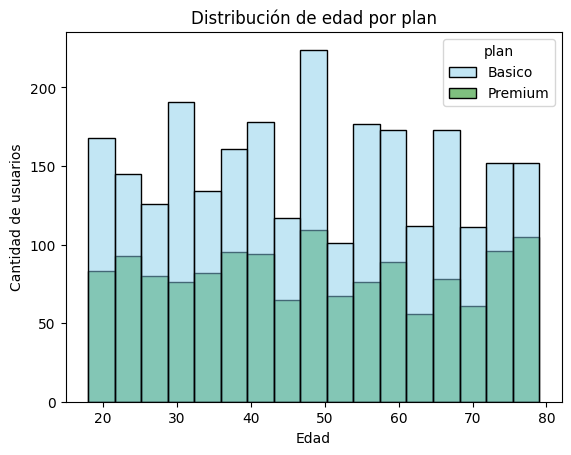

In [52]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue', 'green'])
plt.title('Distribución de edad por plan')
plt.xlabel('Edad')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights:
- Distribución **aproximadamente uniforme**: los usuarios se reparten de forma pareja entre los 18 y 79 años, sin un pico dominante ni sesgo claro (media 48.1 y mediana 48 casi iguales).
- Ambos planes siguen un patrón similar en todas las edades. Proporcionalmente, el plan Premium tiene una presencia algo mayor en los usuarios de más de 70 años.
- Después de reemplazar el sentinel -999, no quedan edades fuera de un rango lógico.

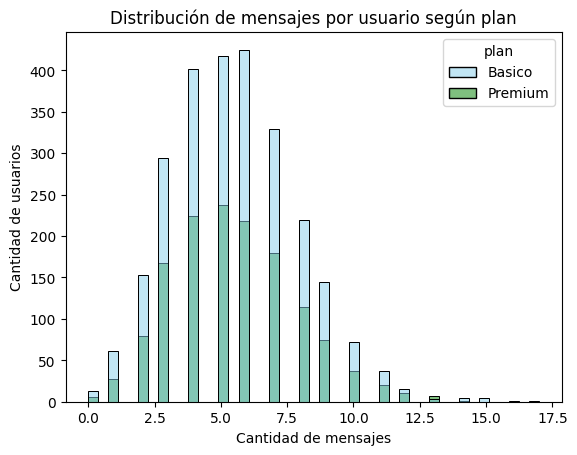

In [53]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue', 'green'])
plt.title('Distribución de mensajes por usuario según plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights:
- Distribución **ligeramente sesgada a la derecha**: la mayoría de usuarios envía entre 3 y 7 mensajes (pico en 5–6), y unos pocos llegan hasta 17.
- Los usuarios Básico y Premium tienen la misma forma de distribución: **no existe un patrón** que indique que los usuarios Premium envíen más mensajes.
- El uso está muy por debajo de lo que incluyen los planes (100 mensajes en Básico y 500 en Premium), lo que sugiere que los clientes Premium no aprovechan el beneficio extra de mensajes.

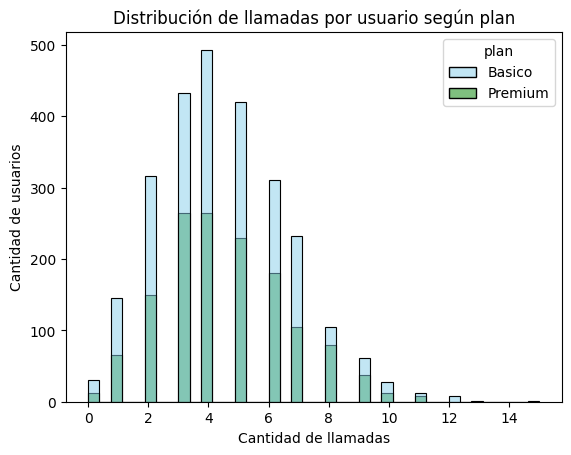

In [54]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue', 'green'])
plt.title('Distribución de llamadas por usuario según plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights:
- Distribución **ligeramente sesgada a la derecha**: la mayoría de usuarios hace entre 2 y 6 llamadas (pico en 4), con pocos casos que llegan a 12–15.
- Ambos planes muestran la misma forma: **no existe un patrón** claro de mayor número de llamadas en usuarios Premium.
- Hay un pequeño grupo de usuarios con 0 llamadas, que solo usan mensajes o casi no usan el servicio.

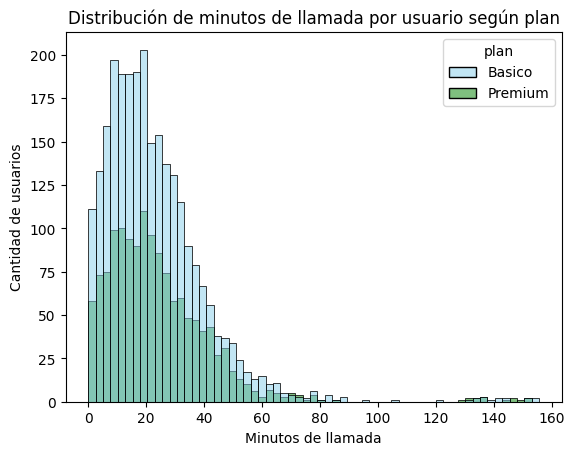

In [55]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue', 'green'])
plt.title('Distribución de minutos de llamada por usuario según plan')
plt.xlabel('Minutos de llamada')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights:
- Distribución **sesgada a la derecha**: la mayoría de usuarios consume entre 5 y 40 minutos, y la cola se extiende hasta 155 minutos (media 23.3 mayor que mediana 19.8).
- Se observa un **grupo aislado entre 125 y 155 minutos**, formado principalmente por usuarios **Premium**. Son posibles outliers que se revisarán en el paso 5.2.
- Fuera de ese grupo, ambos planes tienen un consumo similar y muy por debajo de los minutos incluidos (100 en Básico y 600 en Premium).

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

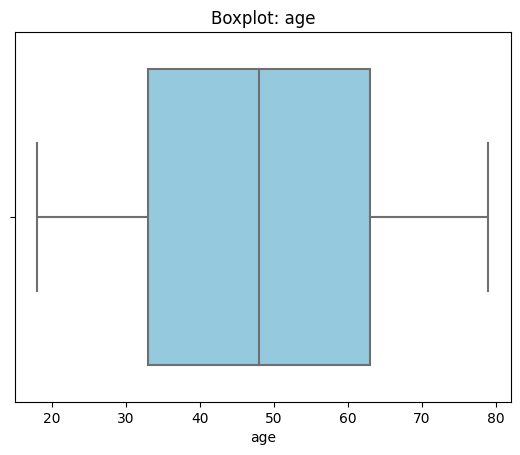

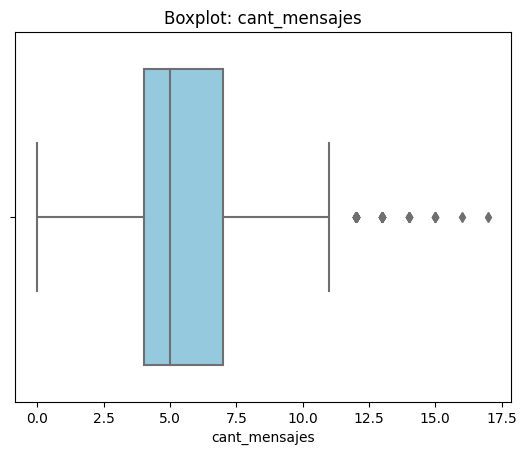

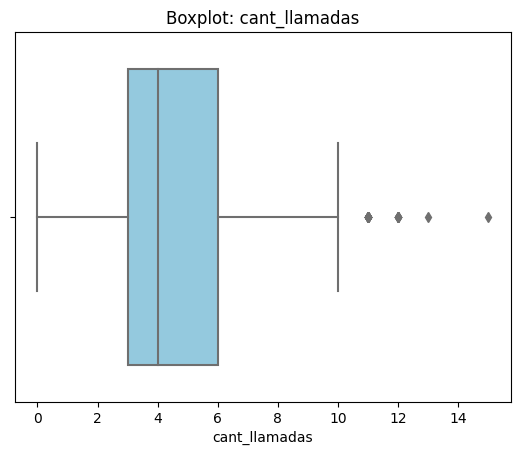

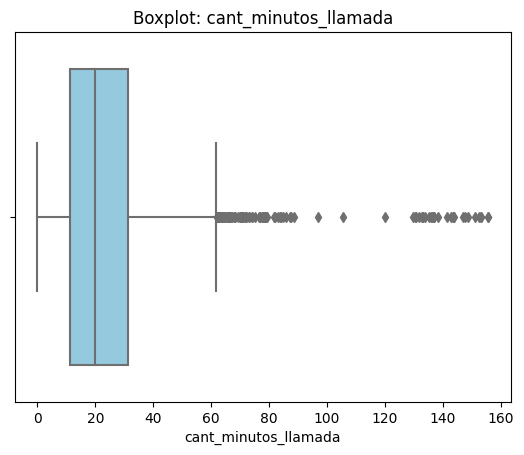

In [56]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(x=user_profile[col], color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights:
- **Age:** no presenta outliers. Todos los valores (18 a 79 años) están dentro de los bigotes y la mediana (48) está centrada en el cajón, lo que confirma una distribución equilibrada.
- **cant_mensajes:** presenta outliers solo hacia la derecha, entre 12 y 17 mensajes. La mayoría de usuarios envía entre 4 y 7 mensajes.
- **cant_llamadas:** presenta outliers solo hacia la derecha, entre 11 y 15 llamadas. La mayoría de usuarios hace entre 3 y 6 llamadas.
- **cant_minutos_llamada:** es la variable con más outliers, todos hacia la derecha. Hay una cola continua entre 62 y 90 minutos, y un **grupo separado entre 120 y 155 minutos**, muy alejado del resto de usuarios.

In [57]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    cant_outliers = (user_profile[col] > limite_superior).sum()
    print(f"{col}: límite superior = {limite_superior}, outliers = {cant_outliers}")

cant_mensajes: límite superior = 11.5, outliers = 46
cant_llamadas: límite superior = 10.5, outliers = 30
cant_minutos_llamada: límite superior = 61.870000000000005, outliers = 109


In [ ]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

💡Insights:
- **cant_mensajes:** se **mantienen** los outliers. Son 46 usuarios (1.15%) por encima del límite de 11.5, con un máximo de 17 mensajes. Son valores realistas que representan usuarios más activos, no errores de captura.
- **cant_llamadas:** se **mantienen** los outliers. Son 30 usuarios (0.75%) por encima del límite de 10.5, con un máximo de 15 llamadas. Es un consumo posible y refleja usuarios intensivos reales.
- **cant_minutos_llamada:** se **mantienen** los outliers, pero se **marcan para revisión**. Son 109 usuarios (2.7%) por encima del límite de 61.9 minutos. Los valores entre 62 y 90 minutos son una continuación natural de la distribución. En cambio, el grupo entre 120 y 155 minutos, formado principalmente por usuarios Premium, está separado del resto y podría indicar un comportamiento inusual (uso empresarial, reventa de minutos o error de registro), por lo que conviene investigarlo con el área de negocio antes de excluirlo.

En los tres casos, eliminar los outliers ocultaría a los clientes de mayor consumo, que son justamente un segmento relevante para el diseño de planes.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [58]:
# Crear columna grupo_uso
user_profile['grupo_uso'] = np.where(
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    'Bajo uso',
    np.where(
        (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10),
        'Uso medio',
        'Alto uso'
    )
)

In [59]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


In [60]:
user_profile['grupo_uso'].value_counts()

Uso medio    2943
Bajo uso      779
Alto uso      278
Name: grupo_uso, dtype: int64

### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [61]:
# Crear columna grupo_edad
user_profile['grupo_edad'] = np.where(
    user_profile['age'] < 30,
    'Joven',
    np.where(
        user_profile['age'] < 60,
        'Adulto',
        'Adulto Mayor'
    )
)

In [62]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


In [63]:
user_profile['grupo_edad'].value_counts()

Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64

### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

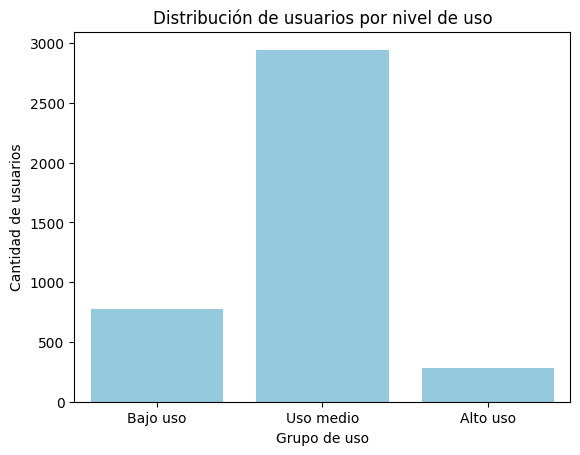

In [64]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso', order=['Bajo uso', 'Uso medio', 'Alto uso'], color='skyblue')
plt.title('Distribución de usuarios por nivel de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.show()

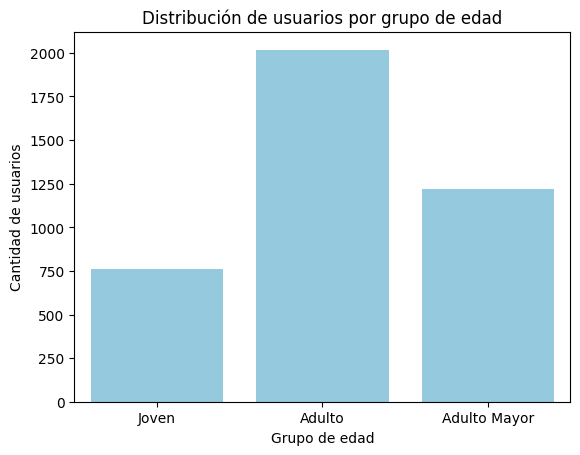

In [65]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad', order=['Joven', 'Adulto', 'Adulto Mayor'], color='skyblue')
plt.title('Distribución de usuarios por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')
plt.show()

In [66]:
pd.crosstab(user_profile['grupo_edad'], user_profile['grupo_uso'], normalize='index') * 100

grupo_uso,Alto uso,Bajo uso,Uso medio
grupo_edad,,,
Adulto,7.581764,18.087215,74.331021
Adulto Mayor,6.055646,21.031097,72.913257
Joven,6.710526,20.657895,72.631579



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- `age`: 55 usuarios (1.4%) tenían el sentinel **-999**, que distorsionaba la edad promedio (33.7 en lugar de 48.1). Se reemplazó por la mediana (48).
- `city`: 469 nulos más 96 registros con el sentinel **"?"**, en total 565 usuarios sin ciudad (14.1%). Se dejaron como nulos.
- `reg_date`: 40 usuarios (1%) con año **2026**, una fecha imposible para datos guardados hasta 2024. Se marcaron como nulos.
- `usage`: 50 registros sin fecha (0.13%) y nulos estructurales en `duration` (55.2%) y `length` (44.7%), que son MAR porque dependen del tipo de registro (llamada o mensaje).
- Un usuario no tenía registros de uso y se completó con 0.


🔍 **Segmentos por Edad**
- **Adulto (30–59 años)** es el grupo principal, con 2,018 usuarios (50.5%), seguido de **Adulto Mayor (60+)** con 1,222 (30.6%) y **Joven (<30)** con 760 (19.0%).
- El nivel de uso es **muy similar entre grupos de edad**: en los tres, entre el 72.6% y el 74.3% de los usuarios está en Uso medio.
- Los **Adultos** son el grupo ligeramente más activo: tienen la mayor proporción de Alto uso (7.6%) y la menor de Bajo uso (18.1%).
- Los **Adultos Mayores** tienen la mayor proporción de Bajo uso (21.0%) y la menor de Alto uso (6.1%). Los **Jóvenes** quedan en un punto intermedio (6.7% Alto uso y 20.7% Bajo uso).
- El plan Premium tiene una presencia proporcionalmente mayor entre los usuarios de más de 70 años, aunque este grupo no consume más que el resto.


📊 **Segmentos por Nivel de Uso**
- **Uso medio** concentra a la gran mayoría: 2,943 usuarios (73.6%). **Bajo uso** agrupa a 779 (19.5%) y **Alto uso** a 278 (7.0%).
- En promedio, cada usuario realizó 4.5 llamadas, envió 5.5 mensajes y consumió 23.3 minutos en 2024.
- Los usuarios Básico y Premium tienen patrones de uso muy similares: el plan Premium **no se traduce en mayor consumo**.
- Se detectaron outliers hacia arriba en mensajes (46 usuarios), llamadas (30) y minutos (109). Destaca un **grupo aislado de 120 a 155 minutos**, formado principalmente por usuarios Premium.


➡️ Esto sugiere que la mayoría de los clientes usa muy poco de lo que incluyen sus planes (100 minutos y 100 mensajes en Básico; 600 minutos y 500 mensajes en Premium). Los usuarios Premium pagan más del doble (USD 25 vs. USD 12) por una capacidad que no aprovechan, lo que representa un **riesgo de insatisfacción o migración** a un plan más barato o a la competencia. Además, como la edad no marca diferencias relevantes en el consumo, las ofertas deberían diseñarse principalmente según el **nivel de uso** y no según la edad del cliente.


💡 **Recomendaciones**
- **Revisar la propuesta del plan Premium:** agregar beneficios de valor percibido (datos, servicios adicionales) en lugar de más minutos y mensajes que no se usan.
- **Crear un plan de entrada más económico** para el segmento de Bajo uso (19.5%), para retenerlo y atraer clientes sensibles al precio.
- **Cuidar al segmento de Alto uso (7%)** con beneficios de fidelización, porque son los clientes más activos.
- **Investigar el grupo de 120–155 minutos** para confirmar si es uso empresarial legítimo, reventa o un error de registro, antes de tomar decisiones comerciales sobre él.
- **Ofrecer a los Adultos Mayores con plan Premium y bajo consumo una migración al plan Básico o a un plan intermedio**, para mejorar su satisfacción y reducir el riesgo de cancelación.
- **Mejorar la captura de datos** (validación de edad, ciudad y fecha de registro) para evitar sentinels y fechas imposibles en el futuro.

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- `age`: 55 usuarios (1.4%) tenían el sentinel **-999**, que distorsionaba la edad promedio (33.7 en lugar de 48.1). Se reemplazó por la mediana (48).
- `city`: 469 nulos más 96 registros con el sentinel **"?"**, en total 565 usuarios sin ciudad (14.1%). Se dejaron como nulos.
- `reg_date`: 40 usuarios (1%) con año **2026**, una fecha imposible para datos guardados hasta 2024. Se marcaron como nulos.
- `usage`: 50 registros sin fecha (0.13%) y nulos estructurales en `duration` (55.2%) y `length` (44.7%), que son MAR porque dependen del tipo de registro (llamada o mensaje).
- Un usuario no tenía registros de uso y se completó con 0.


🔍 **Segmentos por Edad**
- **Adulto (30–59 años)** es el grupo principal, con 2,018 usuarios (50.5%), seguido de **Adulto Mayor (60+)** con 1,222 (30.6%) y **Joven (<30)** con 760 (19.0%).
- El nivel de uso es **muy similar entre grupos de edad**: en los tres, entre el 72.6% y el 74.3% de los usuarios está en Uso medio.
- Los **Adultos** son el grupo ligeramente más activo: tienen la mayor proporción de Alto uso (7.6%) y la menor de Bajo uso (18.1%).
- Los **Adultos Mayores** tienen la mayor proporción de Bajo uso (21.0%) y la menor de Alto uso (6.1%). Los **Jóvenes** quedan en un punto intermedio (6.7% Alto uso y 20.7% Bajo uso).
- El plan Premium tiene una presencia proporcionalmente mayor entre los usuarios de más de 70 años, aunque este grupo no consume más que el resto.


📊 **Segmentos por Nivel de Uso**
- **Uso medio** concentra a la gran mayoría: 2,943 usuarios (73.6%). **Bajo uso** agrupa a 779 (19.5%) y **Alto uso** a 278 (7.0%).
- En promedio, cada usuario realizó 4.5 llamadas, envió 5.5 mensajes y consumió 23.3 minutos en 2024.
- Los usuarios Básico y Premium tienen patrones de uso muy similares: el plan Premium **no se traduce en mayor consumo**.
- Se detectaron outliers hacia arriba en mensajes (46 usuarios), llamadas (30) y minutos (109). Destaca un **grupo aislado de 120 a 155 minutos**, formado principalmente por usuarios Premium.


➡️ Esto sugiere que la mayoría de los clientes usa muy poco de lo que incluyen sus planes (100 minutos y 100 mensajes en Básico; 600 minutos y 500 mensajes en Premium). Los usuarios Premium pagan más del doble (USD 25 vs. USD 12) por una capacidad que no aprovechan, lo que representa un **riesgo de insatisfacción o migración** a un plan más barato o a la competencia. Además, como la edad no marca diferencias relevantes en el consumo, las ofertas deberían diseñarse principalmente según el **nivel de uso** y no según la edad del cliente.


💡 **Recomendaciones**
- **Revisar la propuesta del plan Premium:** agregar beneficios de valor percibido (datos, servicios adicionales) en lugar de más minutos y mensajes que no se usan.
- **Crear un plan de entrada más económico** para el segmento de Bajo uso (19.5%), para retenerlo y atraer clientes sensibles al precio.
- **Cuidar al segmento de Alto uso (7%)** con beneficios de fidelización, porque son los clientes más activos.
- **Investigar el grupo de 120–155 minutos** para confirmar si es uso empresarial legítimo, reventa o un error de registro, antes de tomar decisiones comerciales sobre él.
- **Ofrecer a los Adultos Mayores con plan Premium y bajo consumo una migración al plan Básico o a un plan intermedio**, para mejorar su satisfacción y reducir el riesgo de cancelación.
- **Mejorar la captura de datos** (validación de edad, ciudad y fecha de registro) para evitar sentinels y fechas imposibles en el futuro.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`